# Hedging the Dollar Assets of a Colombian Pension Fund: Rolling Peso Forwards at One, Three, Six and Twelve Months, Hedge Ratios for Equities and Bonds, Settlement Liquidity, and Machine-Learning Dynamic Hedging

Colombian pension funds hold a large share of their assets abroad, mostly in dollars, while their members' pensions are paid in pesos. Every dollar asset therefore carries two risks: the asset's own and the peso's. The funds hedge part of the currency risk with **forwards and FX swaps**, contracts that sell dollars for pesos at a future date at a price fixed today. Three questions decide how:

1. **How much to hedge?** The peso is a commodity- and risk-sensitive currency: it tends to fall when global stocks fall. An unhedged dollar equity holding therefore pays off in pesos precisely when the stocks lose, a natural diversifier. Hedging it could raise risk, not lower it. For bonds, whose dollar returns are steady, the peso is most of the risk.
2. **At what tenor?** Short forwards rolled monthly track the exposure closely but must be settled every month. When the peso falls sharply, the fund pays large amounts in cash at the worst moment. Longer forwards defer the settlement but lock in a rate for longer.
3. **What does it cost?** The forward price embeds the interest-rate differential. Peso rates are higher than dollar rates, so selling dollars forward *earns* the differential (the **carry**): for a Colombian investor, hedging pays rather than costs, on average.

The notebook answers them on fifteen years of real data and then tests whether **machine learning** can set a better hedge ratio each month than a fixed rule:

- **Hedge costs from real trades:** the implied devaluation of forwards bought and sold by Colombian residents, published daily by Banco de la República by maturity bucket.
- **Portfolios:** global equities (MSCI ACWI), U.S. investment-grade bonds (Bloomberg U.S. Aggregate) and a 60/40 mix, held in dollars and measured in pesos.
- **Strategies:** unhedged; 50% and 100% hedged with forwards rolled every 1, 3, 6 or 12 months; the rolling minimum-variance hedge ratio; and two models that predict the peso and set the hedge ratio each month, LightGBM on macro and market signals and a small LSTM on their recent history, both trained up to 2018 and tested from 2019.

**Data.** Banco de la República (implied devaluation and amounts of resident forward trades by maturity; IBR); datos.gov.co (official exchange rate, TRM); Yahoo Finance (ACWI and AGG ETFs, total return); FRED (VIX, broad dollar index, Brent, Treasury bills).

**Methods.** Forward pricing and rolling-hedge accounting with mark-to-market, carry decomposition, minimum-variance hedge ratios, drawdown and CVaR, settlement cash-flow stress, LightGBM and LSTM forecasts of peso depreciation, out-of-time evaluation.

**Key output.** Return, volatility, drawdown and tail risk in pesos for every strategy and asset; the carry earned by hedging; the cash the fund must find to settle its hedges in the worst months; and whether dynamic hedge ratios beat fixed ones out of time.

## 1. The arithmetic of a rolling hedge

A fund holds a dollar portfolio worth $V_t$ dollars; the exchange rate $S_t$ is pesos per dollar. To hedge a fraction $h$ for $\tau$ months, it sells $hV_t$ dollars forward at

$$F_t = S_t\,(1 + d_t)^{\tau/12},$$

where $d_t$ is the annual **implied devaluation** in the forward market (by covered interest parity, roughly the peso–dollar interest differential plus the cross-currency basis). At maturity the forward settles in cash, $hV_t\,(F_t - S_{t+\tau})$ pesos, and a new forward is struck. In pesos the fund's return over the period is the dollar return of the assets, the change in the exchange rate, and the hedge:

$$R^{COP} \approx R^{USD} + \Delta s - h\,(\Delta s - d_t\,\tau/12).$$

With $h = 1$ the peso move is replaced by the forward premium: the fund earns the dollar return plus $d_t$, the carry. Between settlements, open forwards are marked to market with the implied devaluation for the remaining time.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import certifi
import lightgbm as lgb
import torch
import torch.nn as nn
import yfinance as yf

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
NDF_URL = "https://d1b4gd4m8561gs.cloudfront.net/sites/default/files/ndf-negociacion-devaluacion-residente.xlsx"
BANREP = "https://suameca.banrep.gov.co/graficador-series/rest/graficadorService/consultaSerieParaGraficar?idSerie={}"
BANREP_SERIES = {"ibr_1m": 242, "ibr_3m": 243}
TRM_URL = "https://www.datos.gov.co/resource/32sa-8pi3.json"
FRED_SERIES = {
    "vix": "VIXCLS",
    "dollar": "DTWEXBGS",
    "brent": "DCOILBRENTEU",
    "tb_3m": "DTB3",
}
ASSETS = {"ACWI": "global equities", "AGG": "U.S. bonds"}
# months → forward maturity bucket
TENORS = {1: "15-35", 3: "61-90", 6: "91-180", 12: ">180"}
TRAIN_END, TEST_START = "2018-12-31", "2019-01-31"

print(
    f"lightgbm {lgb.__version__} · torch {torch.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

lightgbm 4.7.0 · torch 2.14.1+cu130 · run on 2026-11-13


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Data

Banco de la República's statistics server omits an intermediate certificate; the public certificate in `certs/` is added to the trusted bundle (verification stays on). The forward file reports, for each trading day and maturity bucket, the amounts and implied devaluation of forwards bought and sold by residents. Each month's implied devaluation per bucket is the amount-weighted median of the day-bucket records of at least USD 1 million, with implausible values (outside −30% to +60% a year) dropped. The ETFs' adjusted prices include reinvested distributions.

In [3]:
BUNDLE = DATA_DIR / "ca_bundle_banrep.pem"
BUNDLE.write_text(
    Path(os.environ.get("REQUESTS_CA_BUNDLE") or certifi.where()).read_text()
    + "\n"
    + (PROJECT_DIR / "certs" / "geotrust_ev_rsa_ca_g2.pem").read_text()
)


def fetch_ndf():
    r = requests.get(NDF_URL, timeout=300, headers=BROWSER_HEADERS)
    r.raise_for_status()
    raw = pd.read_excel(io.BytesIO(r.content), header=None)
    hdr = raw.iloc[6].ffill()
    out = []
    for side, start in [("buy", 0), ("sell", 14)]:
        body = raw.iloc[8:, start : start + 13].copy()
        body = body[pd.to_datetime(body.iloc[:, 0], errors="coerce").notna()]
        dates = pd.to_datetime(body.iloc[:, 0])
        for j in range(1, 13, 2):
            out.append(
                pd.DataFrame({
                    "date": dates.to_numpy(),
                    "side": side,
                    "bucket": str(hdr.iloc[start + j]),
                    "amount": (
                        pd.to_numeric(
                            body.iloc[:, j], errors="coerce"
                        ).to_numpy()
                    ),
                    "dev": (
                        pd.to_numeric(
                            body.iloc[:, j + 1], errors="coerce"
                        ).to_numpy()
                    ),
                })
            )
    return pd.concat(out, ignore_index=True)


def fetch_banrep():
    out = {}
    for name, sid in BANREP_SERIES.items():
        r = requests.get(
            BANREP.format(sid),
            timeout=120,
            verify=str(BUNDLE),
            headers=BROWSER_HEADERS,
        )
        r.raise_for_status()
        out[name] = pd.Series(
            {
                pd.to_datetime(t, unit="ms").normalize(): v
                for t, v in r.json()[0]["data"]
            },
            dtype=float,
        )
    return pd.DataFrame(out).sort_index()


def fetch_trm():
    r = requests.get(
        TRM_URL,
        params={
            "$select": "vigenciadesde, valor",
            "$limit": 50_000,
            "$where": "vigenciadesde >= '2008-01-01'",
        },
        timeout=300,
    )
    r.raise_for_status()
    t = pd.DataFrame(r.json())
    return pd.DataFrame(
        {"trm": pd.to_numeric(t["valor"]).to_numpy()},
        index=pd.to_datetime(t["vigenciadesde"]),
    )


def fetch_etf():
    d = {}
    for t in ASSETS:
        x = yf.download(
            t, start="2008-01-01", progress=False, auto_adjust=True
        )["Close"]
        d[t] = x.iloc[:, 0] if isinstance(x, pd.DataFrame) else x
    return pd.DataFrame(d)


NDF = cached("ndf_residents", fetch_ndf, max_age_hours=24 * 7)
BR = cached("banrep_ibr_daily", fetch_banrep, max_age_hours=24 * 7)
TRM = cached("trm_daily", fetch_trm, max_age_hours=24)
ETF = cached("etf_total_return", fetch_etf, max_age_hours=24)
FR = cached(
    "fred_series",
    lambda: pd.DataFrame({
        k: fred.get_series(v, observation_start="2008-01-01")
        for k, v in FRED_SERIES.items()
    }),
    max_age_hours=24,
)
for f_ in (BR, TRM, ETF, FR):
    f_.index = pd.to_datetime(f_.index)

N = NDF[(NDF.amount >= 1e6) & NDF.dev.between(-0.3, 0.6)].copy()
N["month"] = pd.to_datetime(N.date).dt.to_period("M").dt.to_timestamp("M")


def wmedian(g):
    g = g.sort_values("dev")
    c = g.amount.cumsum()
    return g.dev.iloc[np.searchsorted(c.to_numpy(), c.iloc[-1] / 2)]


# annual implied devaluation, decimal
DEV = (
    N.groupby(["month", "bucket"])[["dev", "amount"]].apply(wmedian).unstack()
)
VOL = N.groupby(["month", "bucket"]).amount.sum().unstack() / 1e9
S = TRM.trm.sort_index().resample("ME").last()
P = ETF.resample("ME").last()
M = (
    pd.DataFrame({"S": S})
    .join(P)
    .join(FR.resample("ME").mean())
    .join(BR.resample("ME").mean())
)
for k, b in TENORS.items():
    M[f"dev_{k}m"] = DEV[b]
M = M.loc["2011-09-30":].dropna(subset=["S", "ACWI", "AGG", "dev_1m"])
M[[f"dev_{k}m" for k in TENORS]] = M[[f"dev_{k}m" for k in TENORS]].ffill(
    limit=2
)
print(
    f"{len(M)} months with forward data, {M.index[0]:%Y-%m} to"
    f" {M.index[-1]:%Y-%m} (the forward file ends"
    f" {pd.to_datetime(NDF.date).max():%Y-%m-%d}); TRM"
    f" {TRM.trm.sort_index().iloc[-1]:,.0f} on {TRM.index.max():%Y-%m-%d}"
)
DEVSUM = pd.DataFrame({
    f"{k} months": {
        "median implied devaluation (%/yr)": 100 * M[f"dev_{k}m"].median(),
        "10th percentile": 100 * M[f"dev_{k}m"].quantile(0.1),
        "90th percentile": 100 * M[f"dev_{k}m"].quantile(0.9),
        "months with trades (%)": 100 * M[f"dev_{k}m"].notna().mean(),
        "median monthly volume (USD bn)": VOL[b].reindex(M.index).median(),
    }
    for k, b in TENORS.items()
}).T
DEVSUM.round(2)

172 months with forward data, 2011-09 to 2025-12 (the forward file ends 2025-12-30); TRM 3,302 on 2026-11-13


,median implied devaluation (%/yr),10th percentile,90th percentile,months with trades (%),median monthly volume (USD bn)
1 months,3.27,0.00,7.01,100.00,0.92
3 months,3.57,0.82,7.98,100.00,0.22
6 months,3.81,1.41,7.50,100.00,0.17
12 months,3.91,1.95,7.35,100.00,0.24


## 4. Backtesting the hedges

Each month, the dollar portfolio is rebalanced (the 60/40 mix monthly) and the hedge book is updated:

- A forward of tenor $\tau$ is struck on the hedge ratio times the portfolio's dollar value at the month's implied devaluation for that bucket, and held to maturity. With a three-month tenor, a third of the book rolls each month (**laddered**), so the fund always holds forwards of every remaining maturity, as funds do in practice.
- Open forwards are marked to market each month at the current exchange rate and the implied devaluation for their remaining time. When a forward matures it is **settled in cash**, a gain or a loss in pesos that the fund must pay or can reinvest.

The peso return of a strategy is the asset's dollar return translated at the new exchange rate plus the change in the value of the hedge book, as a share of the portfolio. Settlement cash flows are recorded separately to measure liquidity needs.

In [4]:
RET_USD = np.log(M[["ACWI", "AGG"]]).diff()
RET_USD["60/40"] = np.log(
    0.6 * np.exp(RET_USD.ACWI) + 0.4 * np.exp(RET_USD.AGG)
)
# peso depreciation (log)
DS = np.log(M.S).diff()


def dev_for(m_left, row):
    """
    Implied devaluation for a remaining maturity of m_left months, from the
    nearest bucket.
    """
    k = min(TENORS, key=lambda kk: abs(kk - m_left))
    v = row[f"dev_{k}m"]
    return row["dev_1m"] if pd.isna(v) else v


def backtest(asset, tenor, h_series):
    """
    Laddered rolling hedge: each month a forward of `tenor` months sells
    h/tenor of the portfolio's dollars; open
    forwards are marked to market; maturing ones settle in cash, which is
    reinvested in (or taken from) the portfolio.
    """
    idx = M.index
    # dollars held, for 1 peso of initial wealth
    A = 1 / M.S.iloc[0]
    # open forwards: [USD notional, strike, months left]
    ladder, out = [], []
    for t in range(1, len(idx)):
        row0, row1 = M.iloc[t - 1], M.iloc[t]
        h = float(h_series.iloc[t - 1])
        if not ladder and t == 1:
            ladder = [
                [h * A / tenor, row0.S * (1 + dev_for(j, row0)) ** (j / 12), j]
                for j in range(1, tenor + 1)
            ]
        else:
            ladder.append([
                h * A / tenor,
                row0.S * (1 + dev_for(tenor, row0)) ** (tenor / 12),
                tenor,
            ])
        mtm0 = sum(
            n * (K - row0.S * (1 + dev_for(m, row0)) ** (m / 12))
            for n, K, m in ladder
        )
        W0 = A * row0.S + mtm0
        A *= np.exp(RET_USD[asset].iloc[t])
        settle, mtm1, new = 0.0, 0.0, []
        for n, K, m in ladder:
            if m - 1 <= 0:
                settle += n * (K - row1.S)
            else:
                mtm1 += n * (
                    K - row1.S * (1 + dev_for(m - 1, row1)) ** ((m - 1) / 12)
                )
                new.append([n, K, m - 1])
        ladder = new
        # settlement gains buy dollars, losses are paid by selling them
        A += settle / row1.S
        W1 = A * row1.S + mtm1
        out.append((idx[t], W1 / W0 - 1, settle / W0, h))
    return pd.DataFrame(
        out, columns=["date", "ret", "settlement", "h"]
    ).set_index("date")


def stats(r, settle=None):
    r = r.dropna()
    eq = (1 + r).cumprod()
    out = {
        "return (%/yr)": 100 * ((1 + r).prod() ** (12 / len(r)) - 1),
        "volatility (%/yr)": 100 * r.std() * np.sqrt(12),
        "max drawdown (%)": 100 * (eq / eq.cummax() - 1).min(),
        "CVaR 5%, monthly (%)": 100 * r[r <= r.quantile(0.05)].mean(),
    }
    out["return / volatility"] = (
        out["return (%/yr)"] / out["volatility (%/yr)"]
    )
    if settle is not None:
        s = settle.dropna()
        out["worst monthly settlement (% of assets)"] = 100 * s.min()
        out["worst 12-month settlements (% of assets)"] = (
            100 * s.rolling(12).sum().min()
        )
    return out


const = lambda h: pd.Series(h, index=M.index)
RES, BT = [], {}
for a in ["ACWI", "AGG", "60/40"]:
    RES.append(
        {"asset": a, "strategy": "unhedged"}
        | stats(backtest(a, 1, const(0.0)).ret)
    )
    for k in TENORS:
        for h in (0.5, 1.0):
            bt = backtest(a, k, const(h))
            BT[(a, k, h)] = bt
            RES.append(
                {
                    "asset": a,
                    "strategy": f"{int(h * 100)}% hedged, {k}-month forwards",
                }
                | stats(bt.ret, bt.settlement)
            )
RES = pd.DataFrame(RES).set_index(["asset", "strategy"])
CARRY = pd.Series(
    {f"{k}-month": 100 * M[f"dev_{k}m"].mean() for k in TENORS},
    name=(
        "average implied devaluation earned by selling dollars forward (%/yr)"
    ),
)
display(CARRY.round(2))
RES.round(2)

1-month    3.65
3-month    3.76
6-month    4.30
12-month   4.13
Name: average implied devaluation earned by selling dollars forward (%/yr), dtype: float64

return (%/yr)  volatility (%/yr)  \
asset strategy                                                           
ACWI  unhedged                                17.14              13.21   
      50% hedged, 1-month forwards            16.14              11.95   
      100% hedged, 1-month forwards           14.65              14.07   
      50% hedged, 3-month forwards            16.22              12.06   
      100% hedged, 3-month forwards           14.78              14.55   
      50% hedged, 6-month forwards            16.58              12.19   
      100% hedged, 6-month forwards           15.51              15.17   
      50% hedged, 12-month forwards           16.46              12.44   
      100% hedged, 12-month forwards          15.29              16.26   
AGG   unhedged                                 6.98              13.02   
      50% hedged, 1-month forwards             6.51               7.21   
      100% hedged, 1-month forwards            5.59               4.64   
      50% hedged, 3-month forwards             6.60               7.18   
      100% hedged, 3-month forwards            5.76               4.84   
      50% hedged, 6-month forwards             6.82               7.05   
      100% hedged, 6-month forwards            6.19               5.39   
      50% hedged, 12-month forwards            6.76               7.18   
      100% hedged, 12-month forwards           6.09               6.61   
60/40 unhedged                                13.19              11.47   
      50% hedged, 1-month forwards            12.42               8.10   
      100% hedged, 1-month forwards           11.17               9.30   
      50% hedged, 3-month forwards            12.51               8.12   
      100% hedged, 3-month forwards           11.33               9.64   
      50% hedged, 6-month forwards            12.81               8.17   
      100% hedged, 6-month forwards           11.92              10.26   
      50% hedged, 12-month forwards           12.71               8.41   
      100% hedged, 12-month forwards          11.75              11.37   

                                      max drawdown (%)  CVaR 5%, monthly (%)  \
asset strategy                                                                 
ACWI  unhedged                                  -17.01                 -5.57   
      50% hedged, 1-month forwards              -19.50                 -6.23   
      100% hedged, 1-month forwards             -23.56                 -8.87   
      50% hedged, 3-month forwards              -19.63                 -6.35   
      100% hedged, 3-month forwards             -24.05                 -9.22   
      50% hedged, 6-month forwards              -20.19                 -6.41   
      100% hedged, 6-month forwards             -24.98                 -9.48   
      50% hedged, 12-month forwards             -20.96                 -6.53   
      100% hedged, 12-month forwards            -26.65                 -9.85   
AGG   unhedged                                  -18.47                 -6.81   
      50% hedged, 1-month forwards              -10.06                 -3.47   
      100% hedged, 1-month forwards             -12.21                 -2.59   
      50% hedged, 3-month forwards              -10.69                 -3.47   
      100% hedged, 3-month forwards             -13.07                 -2.51   
      50% hedged, 6-month forwards              -10.54                 -3.29   
      100% hedged, 6-month forwards             -14.17                 -2.66   
      50% hedged, 12-month forwards             -10.16                 -3.44   
      100% hedged, 12-month forwards            -15.98                 -3.53   
60/40 unhedged                                  -16.07                 -4.94   
      50% hedged, 1-month forwards              -14.49                 -3.56   
      100% hedged, 1-month forwards             -18.66                 -5.52   
      50% hedged, 3-month forwards              -14

## 5. How much to hedge: the minimum-variance hedge ratio

The hedge ratio that minimises the variance of peso returns is

$$h^* = \frac{\mathrm{Cov}(R^{USD} + \Delta s,\ \Delta s)}{\mathrm{Var}(\Delta s)} = 1 + \frac{\mathrm{Cov}(R^{USD}, \Delta s)}{\mathrm{Var}(\Delta s)}.$$

When the asset falls as the peso falls (negative covariance between dollar returns and the peso's *appreciation*, positive with its depreciation), $h^* < 1$: part of the currency exposure is a hedge in itself. It is estimated on rolling 36-month windows and applied to the following month, with one-month forwards.

In [5]:
HSTAR = {}
for a in ["ACWI", "AGG", "60/40"]:
    cov = RET_USD[a].rolling(36).cov(DS)
    HSTAR[a] = (1 + cov / DS.rolling(36).var()).clip(0, 1.5)
HSTAR = pd.DataFrame(HSTAR)
CORR = pd.Series(
    {a: RET_USD[a].corr(DS) for a in ["ACWI", "AGG", "60/40"]},
    name="correlation of dollar return with peso depreciation",
)
for a in ["ACWI", "AGG", "60/40"]:
    bt = backtest(a, 1, HSTAR[a].shift(0).fillna(1.0).clip(0, 1))
    BT[(a, "minvar")] = bt
    RES.loc[(a, "rolling minimum-variance ratio, 1-month forwards"), :] = (
        pd.Series(stats(bt.ret, bt.settlement))
    )
display(CORR.round(2))
HSTAR.describe().loc[["mean", "min", "max"]].round(2)

ACWI    -0.53
AGG     -0.19
60/40   -0.52
Name: correlation of dollar return with peso depreciation, dtype: float64

,ACWI,AGG,60/40
mean,0.43,0.93,0.63
min,0.06,0.74,0.40
max,0.74,1.07,0.83


## 6. Can machine learning set a better hedge ratio?

Each month the models predict the peso's depreciation over the next three months from information available at the month-end:

- **Carry and rates:** the 1- and 12-month implied devaluation, the 3-month IBR minus the Treasury-bill rate.
- **Global risk:** VIX, the broad dollar index (3-month change), Brent (3-month change), the ACWI return over 3 and 12 months.
- **Peso momentum and volatility:** 1-, 3- and 12-month depreciation, realised volatility over 6 months, distance from the 3-year average.

The hedge ratio follows the forecast: $h = \text{clip}(0.5 + z/2,\ 0,\ 1)$, where $z$ is the forecast in units of its training standard deviation. A predicted depreciation lowers the hedge (the fund keeps the dollars that are expected to gain), a predicted appreciation raises it. **LightGBM** uses the current values; a small **LSTM** reads the last 12 months of the same signals. Both are trained on 2011–2018 and refitted each year on all data up to the previous December, and their hedge ratios are tested on 2019–2026 with one-month forwards against the fixed 50% hedge.

In [6]:
F = pd.DataFrame(index=M.index)
F["dev1"], F["dev12"] = M.dev_1m, M.dev_12m
F["ibr_tb"] = M.ibr_3m - M.tb_3m
F["vix"] = M.vix
F["dollar_3m"] = np.log(M.dollar).diff(3)
F["brent_3m"] = np.log(M.brent).diff(3)
F["acwi_3m"], F["acwi_12m"] = (
    RET_USD.ACWI.rolling(3).sum(),
    RET_USD.ACWI.rolling(12).sum(),
)
F["dep_1m"], F["dep_3m"], F["dep_12m"] = (
    DS,
    DS.rolling(3).sum(),
    DS.rolling(12).sum(),
)
F["vol_6m"] = DS.rolling(6).std() * np.sqrt(12)
F["dist_3y"] = np.log(M.S) - np.log(M.S).rolling(36).mean()
Y = DS.rolling(3).sum().shift(-3)  # next three months' depreciation
FEATS = list(F.columns)
D_ = F.join(Y.rename("y")).dropna(subset=FEATS)
years = sorted(set(D_.loc[TEST_START:].index.year))
pred_gbm, pred_lstm = pd.Series(np.nan, index=D_.index), pd.Series(
    np.nan, index=D_.index
)
SEQ = 12


class LSTMNet(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.lstm = nn.LSTM(d, 16, batch_first=True)
        self.head = nn.Linear(16, 1)

    def forward(self, x):
        return self.head(self.lstm(x)[0][:, -1]).squeeze(-1)


def seqs(Xs, idx):
    pos = {d: i for i, d in enumerate(Xs.index)}
    return np.stack([
        Xs.iloc[pos[d] - SEQ + 1 : pos[d] + 1].to_numpy()
        for d in idx
        if pos[d] >= SEQ - 1
    ]), [d for d in idx if pos[d] >= SEQ - 1]


for yr in years:
    cut = pd.Timestamp(f"{yr - 1}-12-31")
    # labels known by the cut-off
    tr = D_[(D_.index <= cut - pd.offsets.MonthEnd(3))].dropna(subset=["y"])
    te = D_[D_.index.year == yr]
    gbm = lgb.LGBMRegressor(
        n_estimators=300,
        learning_rate=0.03,
        num_leaves=8,
        min_child_samples=12,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=SEED,
        verbose=-1,
    ).fit(tr[FEATS], tr.y)
    pred_gbm.loc[te.index] = gbm.predict(te[FEATS])
    mu_, sd_ = tr[FEATS].mean(), tr[FEATS].std()
    Xs = ((D_[FEATS] - mu_) / sd_).fillna(0)
    xtr, itr = seqs(Xs, tr.index)
    xte, ite = seqs(Xs, te.index)
    ytr_ = torch.tensor(
        tr.y.loc[itr].to_numpy() / tr.y.std(), dtype=torch.float32
    )
    torch.manual_seed(SEED + yr)
    net = LSTMNet(len(FEATS))
    opt = torch.optim.Adam(net.parameters(), lr=3e-3, weight_decay=1e-3)
    xt = torch.tensor(xtr, dtype=torch.float32)
    for ep in range(200):
        opt.zero_grad()
        loss = ((net(xt) - ytr_) ** 2).mean()
        loss.backward()
        opt.step()
    with torch.no_grad():
        pred_lstm.loc[ite] = (
            net(torch.tensor(xte, dtype=torch.float32)).numpy() * tr.y.std()
        )
    D_.loc[te.index, "sd_train"] = tr.y.std()

T_ = D_.loc[TEST_START:].dropna(subset=["y"])
FC = pd.DataFrame({
    m: {
        "correlation with realised": T_.y.corr(p.loc[T_.index]),
        "direction right (%)": (
            100 * (np.sign(p.loc[T_.index]) == np.sign(T_.y)).mean()
        ),
        "RMSE vs zero forecast (ratio)": (
            np.sqrt(((p.loc[T_.index] - T_.y) ** 2).mean())
            / np.sqrt((T_.y**2).mean())
        ),
    }
    for m, p in [("LightGBM", pred_gbm), ("LSTM", pred_lstm)]
}).T


def h_from(pred):
    z = pred / D_.sd_train
    return (0.5 + z / 2).clip(0, 1).reindex(M.index)


DYN = []
for a in ["ACWI", "AGG", "60/40"]:
    for name, hs in [
        ("fixed 50%", const(0.5)),
        ("fixed 100%", const(1.0)),
        ("unhedged", const(0.0)),
        ("LightGBM ratio", h_from(pred_gbm).fillna(0.5)),
        ("LSTM ratio", h_from(pred_lstm).fillna(0.5)),
    ]:
        bt = backtest(a, 1, hs)
        BT[(a, "dyn", name)] = bt
        DYN.append(
            {
                "asset": a,
                "strategy": name,
                "average hedge ratio": hs.loc[TEST_START:].mean(),
            }
            | stats(bt.ret.loc[TEST_START:], bt.settlement.loc[TEST_START:])
        )
DYN = pd.DataFrame(DYN).set_index(["asset", "strategy"])
gimp = pd.Series(gbm.booster_.feature_importance("gain"), index=FEATS)
display(FC.round(3))
display(
    (gimp / gimp.sum())
    .sort_values(ascending=False)
    .head(6)
    .round(3)
    .rename("LightGBM gain share (last refit)")
)
DYN.round(2)

,correlation with realised,direction right (%),RMSE vs zero forecast (ratio)
LightGBM,-0.06,55.56,1.37
LSTM,-0.17,48.15,1.97


ibr_tb     0.18
vix        0.16
dev1       0.13
dep_3m     0.09
brent_3m   0.07
dist_3y    0.07
Name: LightGBM gain share (last refit), dtype: float64

average hedge ratio  return (%/yr)  volatility (%/yr)  \
asset strategy                                                                
ACWI  fixed 50%                      0.50          17.36              13.51   
      fixed 100%                     1.00          17.81              16.09   
      unhedged                       0.00          16.42              13.74   
      LightGBM ratio                 0.70          17.77              15.11   
      LSTM ratio                     0.62          20.25              14.25   
AGG   fixed 50%                      0.50           5.42               7.58   
      fixed 100%                     1.00           6.37               5.87   
      unhedged                       0.00           4.06              12.78   
      LightGBM ratio                 0.70           6.14               6.22   
      LSTM ratio                     0.62           8.06               8.50   
60/40 fixed 50%                      0.50          12.70               9.24   
      fixed 100%                     1.00          13.37              11.04   
      unhedged                       0.00          11.57              11.47   
      LightGBM ratio                 0.70          13.25              10.27   
      LSTM ratio                     0.62          15.49              10.18   

                      max drawdown (%)  CVaR 5%, monthly (%)  \
asset strategy                                                 
ACWI  fixed 50%                 -19.50                 -6.53   
      fixed 100%                -23.56                 -9.65   
      unhedged                  -17.01                 -5.53   
      LightGBM ratio            -20.40                 -8.22   
      LSTM ratio                -17.56                 -5.50   
AGG   fixed 50%                 -10.06                 -3.39   
      fixed 100%                -12.21                 -2.92   
      unhedged                  -18.47                 -6.59   
      LightGBM ratio            -11.53                 -2.45   
      LSTM ratio                -11.69                 -4.08   
60/40 fixed 50%                 -14.49                 -3.93   
      fixed 100%                -18.66                 -6.37   
      unhedged                  -16.07                 -4.98   
      LightGBM ratio            -13.31                 -5.01   
      LSTM ratio                -13.50                 -3.61   

                      return / volatility  \
asset strategy                              
ACWI  fixed 50%                      1.29   
      fixed 100%                     1.11   
      unhedged                       1.19   
      LightGBM ratio                 1.18   
      LSTM ratio                     1.42   
AGG   fixed 50%                      0.71   
      fixed 100%                     1.09   
      unhedged                       0.32   
      LightGBM ratio                 0.99   
      LSTM ratio                     0.95   
60/40 fixed 50%                      1.37   
      fixed 100%                     1.21   
      unhedged                       1.01   
      LightGBM ratio                 1.29   
      LSTM ratio                     1.52   

                      worst monthly settlement (% of assets)  \
asset strategy                                                 
ACWI  fixed 50%                                        -7.34   
      fixed 100%                                      -14.68   
      unhedged                                          0.00   
      LightGBM ratio                                  -13.48   
      LSTM ratio                                       -5.78   
AGG   fixed 50%                                        -7.34   
      fixed 100%                                      -14.68   
      unhedged                                          0.00   
      LightGBM ratio                                  -13.48   
      LSTM ratio                                       -5.78   
60/40 fixed 50%                                        

## 7. Charts and dashboard

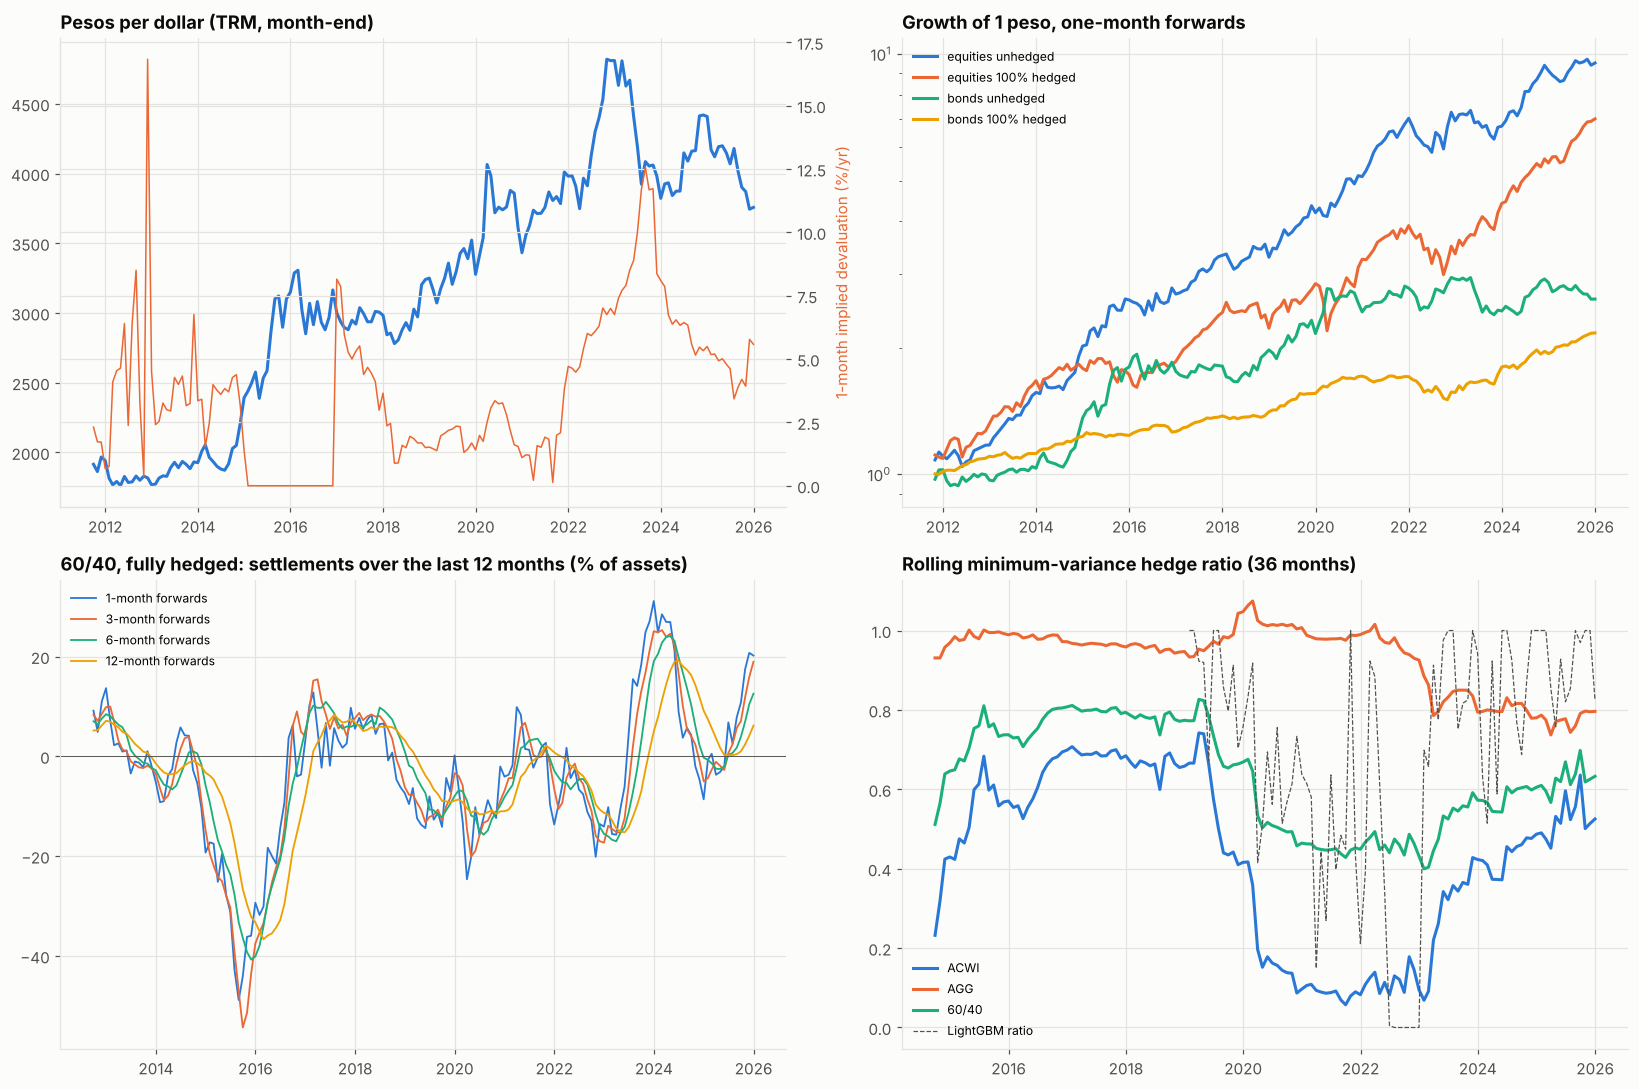

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(15, 10))
a = ax[0, 0]
a.plot(M.index, M.S, color=PALETTE[0])
a.set_title("Pesos per dollar (TRM, month-end)")
a2 = a.twinx()
a2.plot(M.index, 100 * M.dev_1m, color=PALETTE[1], lw=1)
a2.set_ylabel("1-month implied devaluation (%/yr)", color=PALETTE[1])
a = ax[0, 1]
for i_, (k, lab) in enumerate([
    (("ACWI", 1, 0.0), "equities unhedged"),
    (("ACWI", 1, 1.0), "equities 100% hedged"),
    (("AGG", 1, 0.0), "bonds unhedged"),
    (("AGG", 1, 1.0), "bonds 100% hedged"),
]):
    r = backtest(k[0], 1, const(k[2])).ret if k[2] == 0.0 else BT[k].ret
    a.plot(r.index, (1 + r).cumprod(), color=PALETTE[i_], label=lab)
a.set_yscale("log")
a.set_title("Growth of 1 peso, one-month forwards")
a.legend(fontsize=8)
a = ax[1, 0]
for i_, k in enumerate(TENORS):
    s = BT[("60/40", k, 1.0)].settlement.rolling(12).sum() * 100
    a.plot(s.index, s, color=PALETTE[i_], lw=1.2, label=f"{k}-month forwards")
a.axhline(0, color=INK_2, lw=0.6)
a.set_title(
    "60/40, fully hedged: settlements over the last 12 months (% of assets)"
)
a.legend(fontsize=8)
a = ax[1, 1]
for i_, a_ in enumerate(["ACWI", "AGG", "60/40"]):
    a.plot(HSTAR.index, HSTAR[a_], color=PALETTE[i_], label=a_)
a.plot(
    h_from(pred_gbm).index,
    h_from(pred_gbm),
    color=INK_2,
    lw=0.8,
    ls="--",
    label="LightGBM ratio",
)
a.set_title("Rolling minimum-variance hedge ratio (36 months)")
a.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "01_peso_hedging")
plt.show()

In [8]:
dash = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=(
        "Volatility in pesos (%/yr)",
        "Worst 12-month settlements, 100% hedged (% of assets)",
        "Return / volatility, test period 2019–2026",
    ),
)
for i_, a_ in enumerate(["ACWI", "AGG", "60/40"]):
    sub = RES.loc[a_]
    keys = [
        "unhedged",
        "50% hedged, 1-month forwards",
        "100% hedged, 1-month forwards",
    ]
    dash.add_trace(
        go.Bar(
            x=keys,
            y=sub.loc[keys, "volatility (%/yr)"],
            name=a_,
            marker_color=PALETTE[i_],
        ),
        1,
        1,
    )
    dash.add_trace(
        go.Bar(
            x=[f"{k}m" for k in TENORS],
            y=[
                sub.loc[
                    f"100% hedged, {k}-month forwards",
                    "worst 12-month settlements (% of assets)",
                ]
                for k in TENORS
            ],
            name=a_,
            marker_color=PALETTE[i_],
            showlegend=False,
        ),
        1,
        2,
    )
    dash.add_trace(
        go.Bar(
            x=DYN.loc[a_].index,
            y=DYN.loc[a_, "return / volatility"],
            name=a_,
            marker_color=PALETTE[i_],
            showlegend=False,
        ),
        1,
        3,
    )
dash.update_layout(
    height=600,
    width=1500,
    template="simple_white",
    barmode="group",
    title="Hedging the dollar assets of a Colombian pension fund",
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 8. Reading the results and limitations

**The data.** Banco de la República's forward file runs from September 2011 to December 2025, so the backtests cover 172 months. Over that period the peso fell from about 1,840 per dollar to a peak above 5,000 in November 2022 and recovered to about 3,760 by the end of 2025, with large shocks in 2014–15 (oil), 2020 (the pandemic) and 2022.

**Hedging earns the carry, but the peso fell more than the carry paid.** The implied devaluation that a fund earns by selling dollars forward averaged 3.7% a year at one month and 4.1–4.3% at six and twelve months. Over the sample the peso lost more than that, so every hedge reduced peso returns. Unhedged global equities returned 17.1% a year in pesos against 14.7% fully hedged with monthly forwards.

**For equities, the dollar is a hedge; for bonds, it is the risk.** The correlation between dollar returns and the peso's depreciation is −0.53 for global equities and −0.19 for U.S. bonds: when world stocks fall, the peso falls too, and the dollar holding gains in pesos. Volatility in pesos with one-month forwards:

| Asset | Unhedged | 50% hedged | 100% hedged | Rolling minimum-variance ratio (average) |
|---|---|---|---|---|
| Global equities (ACWI) | 13.2% | 12.0% | 14.1% | 0.43 |
| U.S. bonds (AGG) | 13.0% | 7.2% | 4.6% | 0.93 |
| 60/40 | 11.5% | 8.1% | 9.3% | 0.63 |

- **Equities:** fully hedging *raises* risk (volatility 14.1% against 13.2%, drawdown −24% against −17%) and lowers return. The variance-minimising ratio averaged 0.43 and fell as low as 0.06.
- **Bonds:** hedging cuts volatility from 13% to under 5%. Without it, a bond portfolio in pesos is mostly a currency bet.
- **The 60/40 mix:** a 50% hedge gives the lowest volatility (8.1% with monthly forwards) and the best return per unit of risk (1.51–1.57 across tenors), close to the minimum-variance ratio. This is the textbook result of Campbell, Serfaty-de Medeiros and Viceira (2010), seen from a commodity currency.

**Liquidity is the real cost of short tenors.** Fully hedged with monthly forwards, the fund would have had to pay settlements worth 14.7% of its assets in a single month and 49% over the worst twelve months (2014–15), cash raised by selling assets as they fell in dollar terms. Longer tenors spread the bill:

| 60/40, 100% hedged | 1-month | 3-month | 6-month | 12-month |
|---|---|---|---|---|
| Worst monthly settlement | −14.7% | −9.6% | −4.6% | −4.4% |
| Worst 12-month settlements | −49% | −54% | −41% | −37% |
| Volatility | 9.3% | 9.6% | 10.3% | 11.4% |

Six- and twelve-month forwards cut the worst single month to a third and the worst year by a quarter, at the price of a hedge that tracks the exposure less closely (higher volatility). Laddering, with a fraction of the book maturing each month, is what makes longer tenors workable. At 50% hedged, the worst year falls to 15–25% of assets.

**Machine learning cannot forecast the peso well enough to time the hedge.** Out of time (2019–2025, 81 monthly forecasts of the next three months' move):
- **LightGBM:** correlation with the realised move −0.06, right direction 56% of the time.
- **LSTM:** correlation −0.17, right direction 48%. Both forecasts are worse than predicting no change.
- **Hedge ratios in the test period:** the LSTM-driven ratio happened to give the best return per unit of risk (1.52 for the 60/40, against 1.37 for a fixed 50%). With a negative forecast correlation, this is luck in the sequence of 2019–2025 shocks, not skill, and should not be relied on. LightGBM's ratio did no better than the best fixed ratio for each asset (50% for equities and the 60/40, 100% for bonds).

The useful signals in LightGBM were the rate differential (IBR minus T-bills), VIX and the carry itself, the variables of the currency-carry literature. They are not stable enough at a three-month horizon to beat a fixed ratio.

**For a Colombian fund:** hedge bonds almost fully and equities lightly (a combined ratio near 50% for a 60/40 mix), use laddered three- to twelve-month forwards to limit settlement shocks, and keep a liquidity buffer sized for a 15% settlement in one month.

**Limits.**
- **Forward prices:** monthly medians of residents' trades, not executable quotes; the >180-day bucket mixes maturities beyond six months and stands in for 12-month forwards. Long-dated cross-currency swaps are not covered because no public series of their prices exists.
- **Costs:** bid–ask spreads, collateral, credit lines and the funds' regulatory hedging limits are ignored.
- **Assets:** ETFs stand in for the funds' foreign portfolios; actual holdings include other currencies and alternative assets.
- **Sample:** one long peso depreciation dominates the results; a period of appreciation would favour hedging.

In [9]:
DEVSUM.to_csv(OUT_DIR / "implied_devaluation_by_tenor.csv")
RES.to_csv(OUT_DIR / "hedging_strategies_full_sample.csv")
HSTAR.to_csv(OUT_DIR / "rolling_min_variance_hedge_ratios.csv")
FC.to_csv(OUT_DIR / "peso_forecast_accuracy.csv")
DYN.to_csv(OUT_DIR / "dynamic_hedging_test_period.csv")
pd.DataFrame({"LightGBM": pred_gbm, "LSTM": pred_lstm, "realised": Y}).to_csv(
    OUT_DIR / "peso_forecasts.csv"
)
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_peso_hedging.png, dashboard.html, dashboard.png, dynamic_hedging_test_period.csv, hedging_strategies_full_sample.csv, implied_devaluation_by_tenor.csv, peso_forecast_accuracy.csv, peso_forecasts.csv, rolling_min_variance_hedge_ratios.csv


## References

- Banco de la República. *Operaciones de derivados: devaluación implícita y montos de forwards de residentes por plazo*. https://www.banrep.gov.co/es/estadisticas/derivados
- Banco de la República. *Indicador Bancario de Referencia (IBR)*. https://www.banrep.gov.co/es/estadisticas/indicador-bancario-referencia-ibr
- Campbell, J. Y., Serfaty-de Medeiros, K., & Viceira, L. M. (2010). Global currency hedging. *Journal of Finance*, 65(1), 87–121.
- Du, W., Tepper, A., & Verdelhan, A. (2018). Deviations from covered interest rate parity. *Journal of Finance*, 73(3), 915–957.
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation*, 9(8), 1735–1780.
- Ke, G., Meng, Q., Finley, T., et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems*, 30.
- Lustig, H., Roussanov, N., & Verdelhan, A. (2011). Common risk factors in currency markets. *Review of Financial Studies*, 24(11), 3731–3777.
- Perold, A. F., & Schulman, E. C. (1988). The free lunch in currency hedging: Implications for investment policy and performance standards. *Financial Analysts Journal*, 44(3), 45–50.
- Datos Abiertos Colombia. *Tasa de Cambio Representativa del Mercado (TRM)*. https://www.datos.gov.co/
- Federal Reserve Bank of St. Louis. *FRED: VIX, nominal broad dollar index, Brent crude oil, 3-month Treasury bill*. https://fred.stlouisfed.org/